# FinanceGuard — Predicción de Churn Bancario
## Notebook 1: EDA y Regresión Logística

**Autor:** Mauricio Melgarejo


---
## 1. Importación de librerías

In [1]:
# Manipulación de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Modelo y preprocesamiento
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Métricas de evaluación
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    ConfusionMatrixDisplay
)

# Configuración visual
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

print('Librerías importadas correctamente')

Librerías importadas correctamente


## 2. Carga del dataset

In [2]:
# Cargar el dataset
df = pd.read_csv('Churn_Modelling.csv')

# Ver dimensiones y primeras filas
print(f'Filas: {df.shape[0]}')
print(f'Columnas: {df.shape[1]}')
df.head()

Filas: 10000
Columnas: 14


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Dataset de 10.000 clientes bancarios con 14 variables demográficas y financieras.

Cada fila representa un cliente y su comportamiento histórico con el banco.

## 3. Exploración inicial

In [3]:
df.dtypes # Verificar tipos de datos

RowNumber            int64
CustomerId           int64
Surname                str
CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

In [4]:
df.isnull().sum() # Verificar valores faltantes

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [5]:
df.describe().round(2) # Estadísticas descriptivas

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.0
mean,5000.50,15690940.57,650.53,38.92,5.01,76485.89,1.53,0.71,0.52,100090.24,0.2
std,2886.90,71936.19,96.65,10.49,2.89,62397.41,0.58,0.46,0.50,57510.49,0.4
min,1.00,15565701.00,350.00,18.00,0.00,0.00,1.00,0.00,0.00,11.58,0.0
25%,2500.75,15628528.25,584.00,32.00,3.00,0.00,1.00,0.00,0.00,51002.11,0.0
50%,5000.50,15690738.00,652.00,37.00,5.00,97198.54,1.00,1.00,1.00,100193.92,0.0
75%,7500.25,15753233.75,718.00,44.00,7.00,127644.24,2.00,1.00,1.00,149388.25,0.0
max,10000.00,15815690.00,850.00,92.00,10.00,250898.09,4.00,1.00,1.00,199992.48,1.0


**¿Qué muestra describe()?**
- **count**: cantidad de valores — confirma que no hay faltantes
- **mean**: promedio de la variable
- **std**: qué tan dispersos están los valores
- **min / max**: valor mínimo y máximo
- **25%, 50%, 75%**: cómo se distribuyen los valores

**Hallazgos clave:**

**Age — promedio 38.9, rango 18-92**
El cliente típico tiene casi 40 años. El 50% de los clientes tiene entre 32 y 44 años. Hay algunos clientes muy mayores llegando a 92.

**Balance — promedio $76.485 pero 25% tiene saldo 0**
Acá hay algo interesante. El promedio parece razonable pero el 25% de los clientes tiene exactamente $0 en su cuenta. Eso significa que 2.500 clientes abrieron la cuenta pero no depositan nada. La dispersión alta (std $62.397) confirma que hay mucha variedad: algunos con $0 y otros con casi $250.000.

**CreditScore — promedio 650, rango 350-850**
El puntaje crediticio está bastante bien distribuido. El promedio de 650 es un puntaje crediticio normal, ni muy bueno ni muy malo.

**NumOfProducts — promedio 1.53, rango 1-4**
La mayoría de los clientes tiene 1 o 2 productos contratados. Casi nadie tiene 3 o 4.

**Tenure — promedio 5 años, rango 0-10**
Los clientes llevan en promedio 5 años en el banco. La distribución es muy pareja, hay clientes nuevos y clientes con 10 años.

**EstimatedSalary — promedio $100.090**
El salario está muy bien distribuido entre $11 y casi $200.000. No hay concentración en ningún rango particular.

## 4. Análisis del target

In [6]:
# Analizar distribución del target — verificar desbalance de clases
print(df['Exited'].value_counts())
print()
print(df['Exited'].value_counts(normalize=True).round(3) * 100)

Exited
0    7963
1    2037
Name: count, dtype: int64

Exited
0    79.6
1    20.4
Name: proportion, dtype: float64


El gráfico de la Sección 4 muestra que 8 de cada 10 clientes se quedaron 
y solo 2 de cada 10 abandonaron.

Esto parece simple pero tiene una trampa: si el modelo predice siempre 
"este cliente se queda" sin aprender nada, acierta el 80% de las veces. 
Pero los 2.037 clientes que se fueron no los detecta ninguno.

Por eso el accuracy no sirve acá. Usamos Precision, Recall y F1-Score 
que miden específicamente cuántos de los que se van logra detectar el modelo.

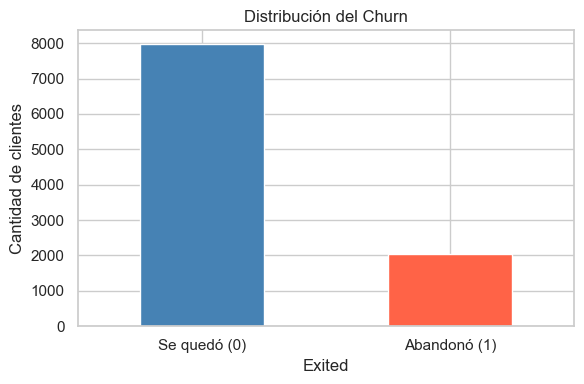

In [7]:
# Visualizar la distribución del churn
fig, ax = plt.subplots(figsize=(6, 4))
df['Exited'].value_counts().plot(kind='bar', 
                                  color=['steelblue', 'tomato'],
                                  ax=ax)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Se quedó (0)', 'Abandonó (1)'], rotation=0)
ax.set_title('Distribución del Churn')
ax.set_ylabel('Cantidad de clientes')
plt.tight_layout()
plt.show()

## 5. Eliminación de columnas sin valor predictivo

In [8]:
# Eliminar columnas identificadoras — no tienen poder predictivo y generan data leakage
df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

# Verificar columnas restantes
print(f'Columnas restantes: {df.shape[1]}')
print(df.columns.tolist())

Columnas restantes: 11
['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


## 6. Análisis de variables numéricas

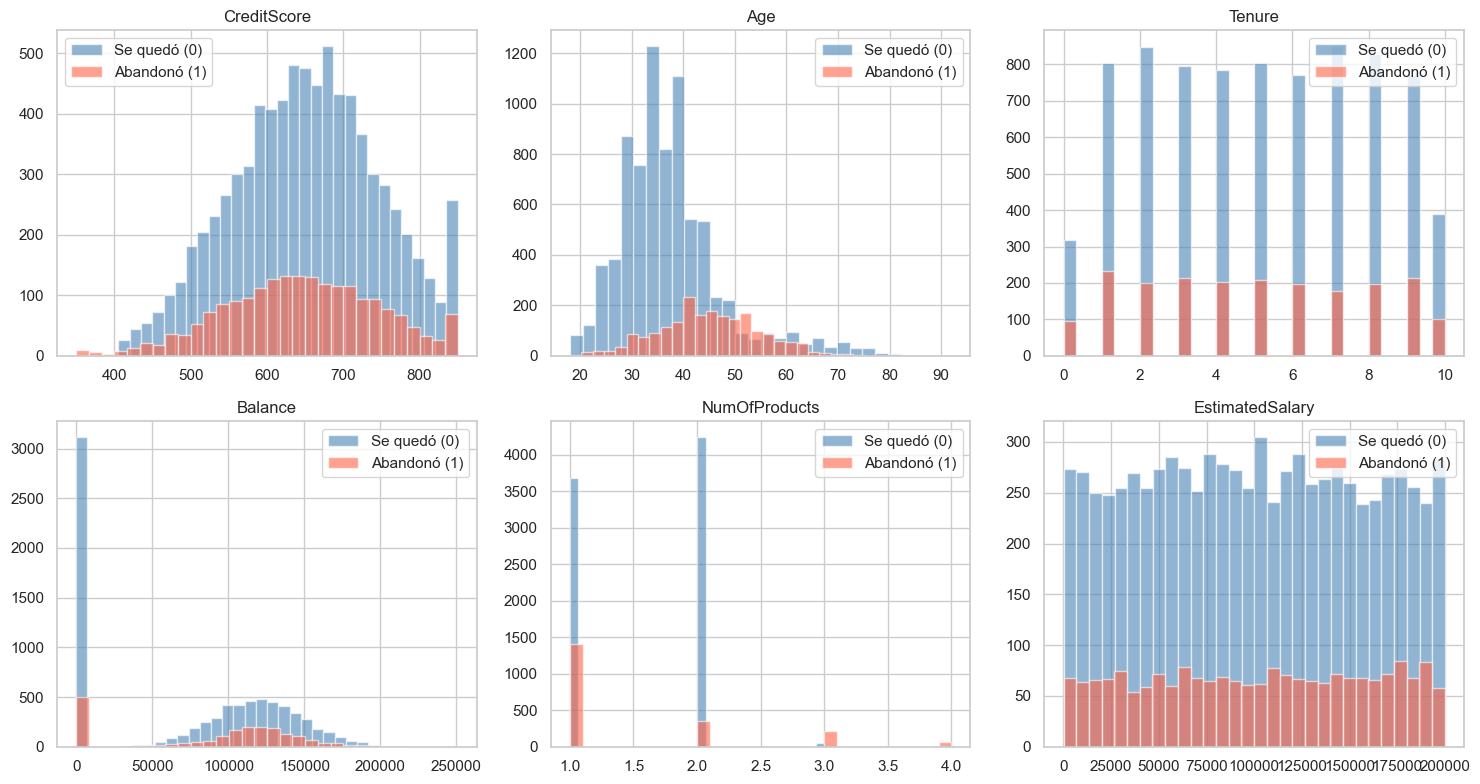

In [9]:
# Comparar la distribución de cada variable numérica entre clientes que se fueron y los que se quedaron
numericas = ['CreditScore', 'Age', 'Tenure', 'Balance',
             'NumOfProducts', 'EstimatedSalary']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(numericas):
    # Distribución de los que se quedaron
    df[df['Exited'] == 0][col].hist(ax=axes[i], alpha=0.6,
                                     label='Se quedó (0)',
                                     color='steelblue', bins=30)
    # Distribución de los que abandonaron
    df[df['Exited'] == 1][col].hist(ax=axes[i], alpha=0.6,
                                     label='Abandonó (1)',
                                     color='tomato', bins=30)
    axes[i].set_title(col)
    axes[i].legend()

plt.tight_layout()
plt.show()

En la Sección 6 el azul representa los clientes que se quedaron 
y el rojo los que abandonaron. Donde los colores se separan, 
esa variable tiene poder para predecir el churn.

- **Age**: el rojo se concentra en clientes mayores de 40 años. Los jóvenes casi no abandonan
- **Balance**: el rojo aparece más en saldos altos entre $100k y $150k. Contraintuitivo: los clientes con más plata son los que más se van
- **NumOfProducts**: el rojo aparece en clientes con 1 producto y también en los que tienen 3 o 4. Los de 2 productos son los más estables
- **CreditScore, Tenure, EstimatedSalary**: azul y rojo casi idénticos — estas variables no ayudan a separar quién se va de quién se queda

## 7. Análisis de variables categóricas

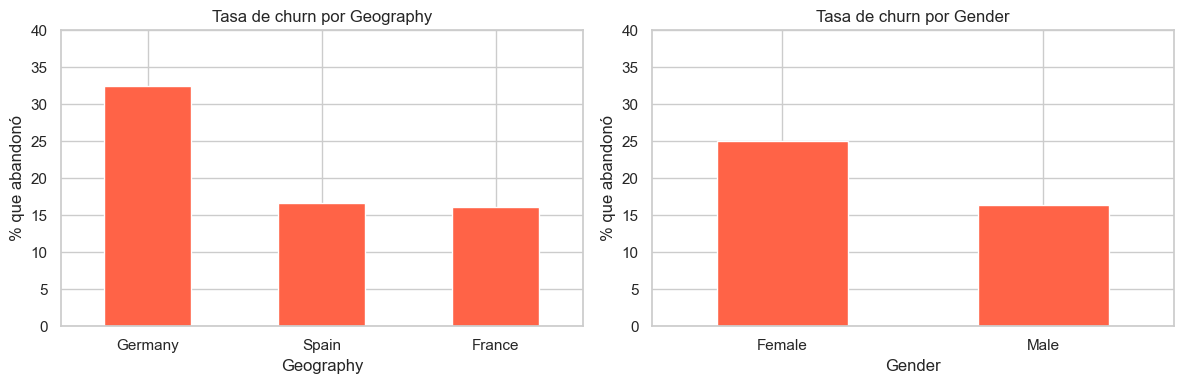

In [10]:
# Calcular tasa de churn por cada categoría de Geography y Gender
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, ['Geography', 'Gender']):
    # Calcular porcentaje de churn por categoría
    churn_rate = df.groupby(col)['Exited'].mean() * 100
    churn_rate.sort_values(ascending=False).plot(
        kind='bar', ax=ax, color='tomato', edgecolor='white', rot=0)
    ax.set_title(f'Tasa de churn por {col}')
    ax.set_ylabel('% que abandonó')
    ax.set_ylim(0, 40)

plt.tight_layout()
plt.show()

En la Sección 7 cada barra muestra qué porcentaje de clientes de ese grupo abandonó el banco.

- **Alemania**: 32% de churn — el doble que Francia y España que rondan el 16%
- **Mujeres**: 25% de churn vs 16% de los hombres

Estos segmentos tienen diferencias claras entre sí, lo que significa que el país y el género 
tienen información útil para predecir quién se va.

Para el equipo de retención del banco esto es accionable: los clientes alemanes 
y las mujeres son los segmentos de mayor riesgo y deberían recibir atención prioritaria.

## 8. Matriz de correlación

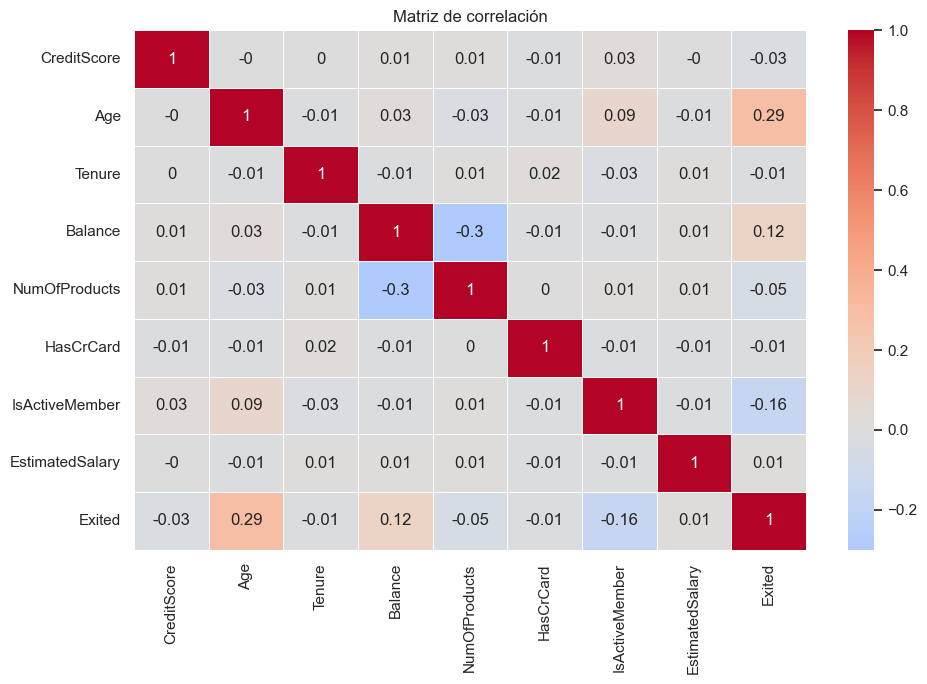

In [11]:
# Calcular y visualizar correlación entre variables numéricas
plt.figure(figsize=(10, 7))
sns.heatmap(
    df.select_dtypes(include='number').corr().round(2),
    annot=True,
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)
plt.title('Matriz de correlación')
plt.tight_layout()
plt.show()

El heatmap de la Sección 8 muestra con colores qué tan relacionadas están las variables entre sí 
y con el churn. Colores cálidos indican relación positiva, fríos indican relación negativa.

Mirando la fila de Exited:
- **Age, Balance e IsActiveMember** tienen los valores más altos — confirman lo que ya vimos 
  visualmente en los histogramas de la Sección 6
- **CreditScore, Tenure y EstimatedSalary** tienen valores cercanos a 0 — poca relación con el churn

Ninguna correlación entre variables supera 0.7, lo que significa que no hay variables 
que digan lo mismo. Todas aportan información diferente y pueden usarse juntas en el modelo.

## 9. Preprocesamiento

### 9.1 Encoding de variables categóricas

In [12]:
# Convertir variables categóricas a numéricas con One-Hot Encoding
# drop_first=True elimina una columna redundante para evitar multicolinealidad
df_encoded = pd.get_dummies(df, columns=['Geography', 'Gender'], drop_first=True)

# Verificar las nuevas columnas creadas
print(df_encoded.columns.tolist())
print(f'Dimensiones: {df_encoded.shape}')

['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']
Dimensiones: (10000, 12)


El modelo solo entiende números, no texto. One-Hot Encoding convierte Geography y Gender 
en columnas de 0 y 1.

Se crean 3 columnas nuevas: Geography_Germany, Geography_Spain y Gender_Male.
France queda implícita cuando Germany=0 y Spain=0.
Female queda implícita cuando Male=0.

Se usa drop_first=True para eliminar una columna redundante por variable 
y evitar que el modelo reciba información duplicada (multicolinealidad).

### 9.2 Separación de features y target

In [13]:
# Separar features (X) y target (y) antes de entrenar
X = df_encoded.drop(columns='Exited')
y = df_encoded['Exited']

# Verificar dimensiones
print(f'Features (X): {X.shape}')
print(f'Target   (y): {y.shape}')

Features (X): (10000, 11)
Target   (y): (10000,)


**Separamos los datos en dos partes antes de entrenar:**

X son las 11 variables que el modelo va a usar para aprender: edad, saldo, país, género, productos, etc.

y es la variable Exited que queremos predecir: 0 = el cliente se quedó, 1 = el cliente abandonó.

Esta separación es necesaria para que el modelo aprenda la relación entre las características del cliente y su decisión de irse o quedarse.

### 9.3 Split train/test

In [14]:
# Dividir en 80% entrenamiento y 20% evaluación
# stratify=y mantiene la proporción de churn en ambos conjuntos
# random_state=42 garantiza reproducibilidad
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Verificar distribución del churn en ambos conjuntos
print(f'Train: {X_train.shape[0]} filas')
print(f'Test:  {X_test.shape[0]} filas')
print(f'Churn en train: {y_train.mean()*100:.1f}%')
print(f'Churn en test:  {y_test.mean()*100:.1f}%')

Train: 8000 filas
Test:  2000 filas
Churn en train: 20.4%
Churn en test:  20.3%


Dividimos el dataset en dos grupos antes de entrenar.
8.000 clientes para que el modelo aprenda y 2.000 para evaluarlo 
con datos que nunca vio.

stratify=y garantiza que el test tenga la misma proporción de churn 
que el banco planteó como problema: 20% de clientes en riesgo.
Así las métricas reflejan lo que pasaría en el mundo real.

### 9.4 Escalamiento de variables numéricas

In [15]:
# Variables a escalar — las categóricas ya están en formato 0/1 y no necesitan escalamiento
cols_escalar = ['CreditScore', 'Age', 'Tenure', 'Balance',
                'NumOfProducts', 'EstimatedSalary']

# fit_transform en train: aprende la escala y la aplica
# transform en test: aplica la misma escala sin recalcularla — evita data leakage
scaler = StandardScaler()
X_train[cols_escalar] = scaler.fit_transform(X_train[cols_escalar])
X_test[cols_escalar]  = scaler.transform(X_test[cols_escalar])

# Verificar que el escalamiento fue correcto
print(f'Media de Age en train: {X_train["Age"].mean():.4f}')
print(f'Std  de Age en train:  {X_train["Age"].std():.4f}')

Media de Age en train: 0.0000
Std  de Age en train:  1.0001


Cada variable tiene su propia escala. Age va de 18 a 92, Balance de 0 a 250.000.

Si no las ajustamos, el modelo le da más importancia a Balance simplemente 
porque es un número más grande, no porque realmente lo sea.

StandardScaler las lleva a todas a la misma escala.

El ajuste se calcula con los datos de entrenamiento únicamente. 
Los datos de test se transforman con esa misma escala aprendida, 
sin volver a calcularla. Así el modelo no recibe información 
que no debería tener al momento de ser evaluado.

## 10. Regresión Logística

In [16]:
# Entrenar Regresión Logística
# max_iter=1000: aumentamos las iteraciones para garantizar convergencia
modelo = LogisticRegression(max_iter=1000, random_state=42)
modelo.fit(X_train, y_train)

print('Modelo entrenado')

Modelo entrenado


Entrenamos una Regresión Logística como primer modelo.

La elegimos porque es el modelo más simple e interpretable: 
sus coeficientes nos dicen exactamente qué variables aumentan 
o reducen el riesgo de churn y en qué magnitud.

Este primer modelo nos sirve como punto de referencia. 
Cualquier modelo más complejo que entrenemos después 
tiene que superar estos resultados para justificar su uso.

## 11. Evaluación del modelo

In [17]:

# Predecir sobre datos de test — datos que el modelo nunca vio durante el entrenamiento
y_pred = modelo.predict(X_test)

# probabilidad de churn para cada cliente
y_pred_prob = modelo.predict_proba(X_test)[:, 1]

# Reporte completo de métricas por clase
print(classification_report(y_test, y_pred, 
      target_names=['Se quedó (0)', 'Abandonó (1)']))

              precision    recall  f1-score   support

Se quedó (0)       0.82      0.97      0.89      1593
Abandonó (1)       0.59      0.19      0.28       407

    accuracy                           0.81      2000
   macro avg       0.71      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000



El modelo evaluó los 2.000 clientes de test:

Para los que se quedaron (0): 
- Precision 0.82 → de cada 10 que predijo como "se queda", 8 realmente se quedaron
- Recall 0.97 → detectó el 97% de los que realmente se quedaron

Para los que abandonaron (1):
- Precision 0.59 → de cada 10 alertas de churn, 6 eran clientes reales en riesgo
- Recall 0.19 → detectó solo el 19% de los que realmente se fueron

Accuracy 0.81: engañoso porque la mayoría son de la clase "se queda"
El Recall de 0.19 en churn significa que 331 clientes abandonaron sin ser detectados. Este es el número que necesitamos mejorar.

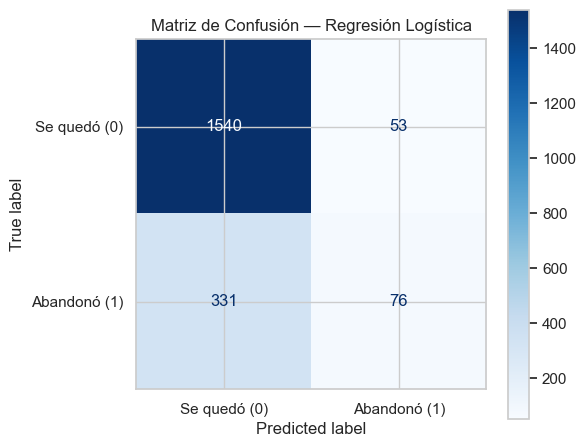

In [18]:
# Visualizar aciertos y errores del modelo por categoría

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Se quedó (0)', 'Abandonó (1)'],
    cmap='Blues',
    ax=ax
)
ax.set_title('Matriz de Confusión — Regresión Logística')
plt.tight_layout()
plt.show()

La matriz muestra exactamente dónde acierta y dónde falla el modelo:

- 1.540 clientes correctamente identificados como activos
- 76 clientes correctamente identificados como churn
- 53 falsas alarmas — el modelo alertó pero el cliente se quedó
- 331 clientes que abandonaron y el modelo no detectó — el error más grave

Los 331 son el problema crítico para el banco: se fueron sin que nadie los contactara. Por cada cliente que detectamos (76), dejamos pasar 4 que no detectamos (331).

### 11.1 Curva ROC

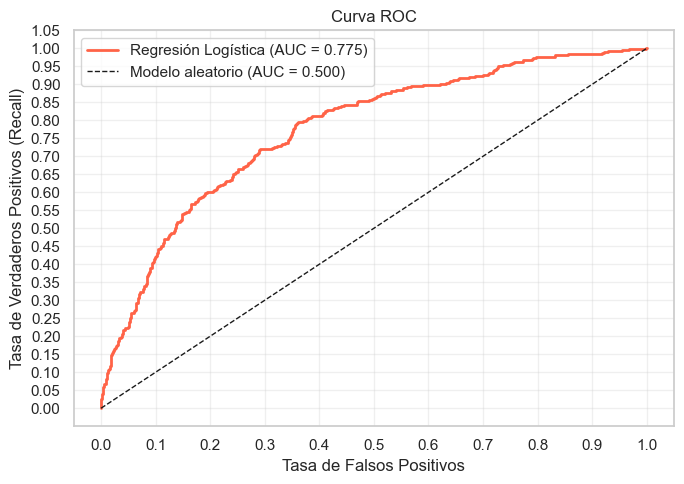

In [30]:
# Calcular los puntos de la curva ROC y el AUC
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
auc = roc_auc_score(y_test, y_pred_prob)

# Visualizar la curva ROC vs modelo aleatorio
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='tomato', lw=2, 
         label=f'Regresión Logística (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1, 
         label='Modelo aleatorio (AUC = 0.500)')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos (Recall)')
plt.title('Curva ROC')
plt.xticks(np.arange(0, 1.1, 0.1))
plt.yticks(np.arange(0, 1.1, 0.05))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

La curva ROC muestra qué tan bien distingue el modelo entre clientes que se van y clientes que se quedan.

- La línea punteada es un modelo que predice al azar (AUC 0.5).
- La línea roja es nuestro modelo (AUC 0.775).

Cuanto más arriba y a la izquierda está la curva roja respecto a la punteada, mejor es el modelo. En este caso el modelo aprende patrones reales pero tiene margen de mejora.

AUC 0.775 significa que en casi 8 de cada 10 comparaciones, el modelo identifica correctamente cuál de dos clientes tiene mayor riesgo de irse.

### 11.2 Curva Precision-Recall y PR-AUC

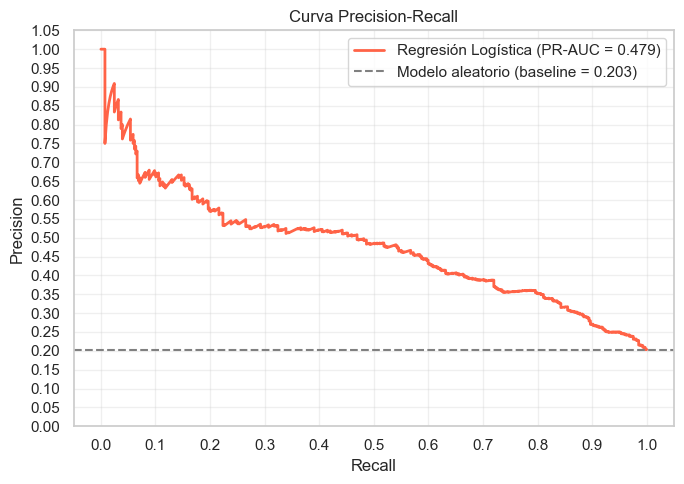

PR-AUC: 0.479
ROC-AUC: 0.775


In [29]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calcular la curva Precision-Recall
precision, recall, _ = precision_recall_curve(y_test, y_pred_prob)
pr_auc = average_precision_score(y_test, y_pred_prob)

# Línea base: tasa de churn real del dataset
baseline = y_test.mean()

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, color='tomato', lw=2,
         label=f'Regresión Logística (PR-AUC = {pr_auc:.3f})')
plt.axhline(baseline, color='gray', linestyle='--',
            label=f'Modelo aleatorio (baseline = {baseline:.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curva Precision-Recall')
plt.xticks(np.arange(0, 1.1, 0.1))
plt.yticks(np.arange(0, 1.1, 0.05))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f'PR-AUC: {pr_auc:.3f}')
print(f'ROC-AUC: {auc:.3f}')

ROC-AUC 0.775 y PR-AUC 0.479 cuentan historias distintas del mismo modelo.

El ROC-AUC evalúa todas las predicciones y parece razonable.
El PR-AUC se enfoca solo en qué tan bien detecta los churns reales y es más exigente con el desbalance 80/20.

El modelo supera el baseline de 0.203 pero tiene margen claro de mejora.

Usamos los dos porque con clases desbalanceadas un solo número puede dar una imagen incompleta del modelo.

### 11.3 Interpretación de coeficientes

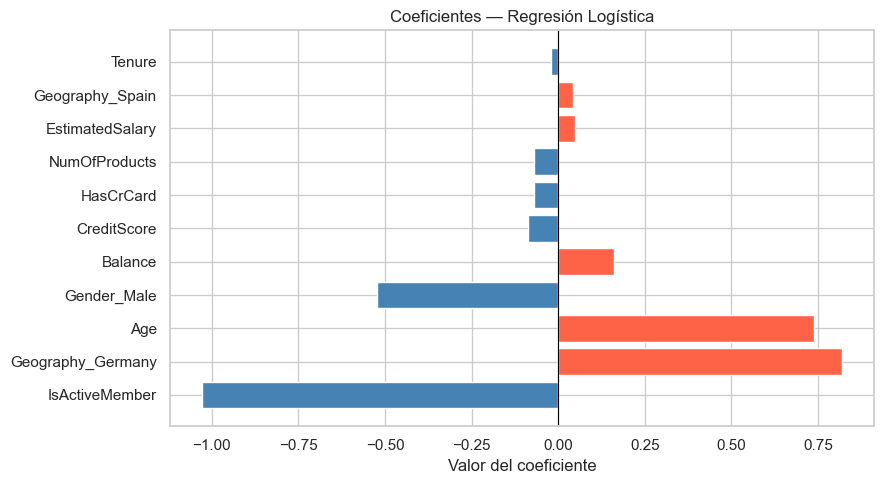

IsActiveMember      -1.0282
Geography_Germany    0.8196
Age                  0.7385
Gender_Male         -0.5232
Balance              0.1611
CreditScore         -0.0859
HasCrCard           -0.0705
NumOfProducts       -0.0704
EstimatedSalary      0.0477
Geography_Spain      0.0425
Tenure              -0.0201
dtype: float64


In [20]:
# Calcular y ordenar los coeficientes por impacto absoluto
coeficientes = pd.Series(
    modelo.coef_[0],
    index=X_train.columns
).sort_values(key=abs, ascending=False)

# Visualizar — rojo aumenta churn, azul lo reduce
plt.figure(figsize=(9, 5))
colores = ['tomato' if c > 0 else 'steelblue' for c in coeficientes]
plt.barh(coeficientes.index, coeficientes.values, 
         color=colores, edgecolor='white')
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Coeficientes — Regresión Logística')
plt.xlabel('Valor del coeficiente')
plt.tight_layout()
plt.show()

# Mostrar valores numéricos
print(coeficientes.round(4))

El gráfico muestra los coeficientes que el modelo asignó a cada variable.
Las barras rojas aumentan el riesgo de churn, las azules lo reducen.
Cuanto más larga la barra, mayor el impacto de esa variable.

- **Age** (rojo): los clientes mayores tienen más probabilidad de abandonar
- **Balance** (rojo): mayor saldo aumenta el riesgo de churn
- **Geography_Germany** (rojo): los clientes alemanes tienen mayor riesgo
- **IsActiveMember** (azul): ser miembro activo reduce el riesgo de churn
- **Gender_Male** (azul): los hombres tienen menor riesgo que las mujeres

Estas variables son las mismas que mostraban diferencias visuales en el EDA 
de la Sección 6 y 7. El modelo aprendió exactamente lo que los datos sugerían.

### 11.4 Odds Ratios

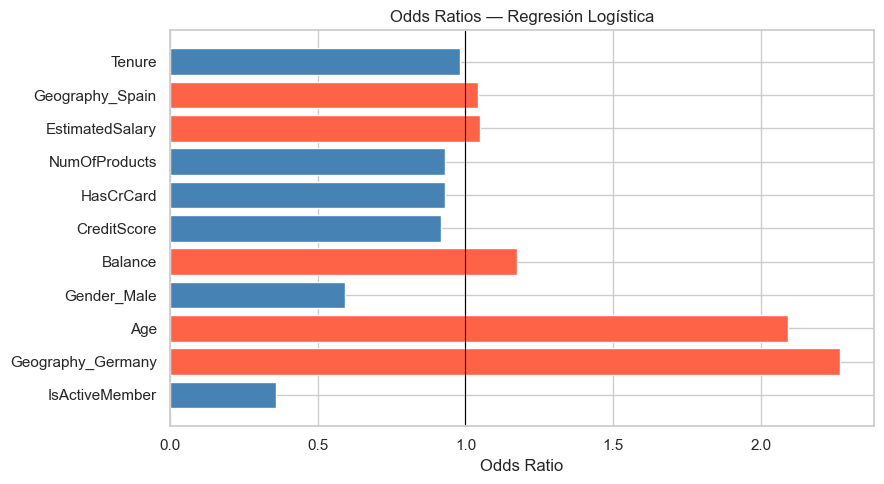

IsActiveMember       0.358
Geography_Germany    2.270
Age                  2.093
Gender_Male          0.593
Balance              1.175
CreditScore          0.918
HasCrCard            0.932
NumOfProducts        0.932
EstimatedSalary      1.049
Geography_Spain      1.043
Tenure               0.980
dtype: float64


In [22]:
# Convertir coeficientes a Odds Ratios "cuántas veces más probable es el churn"
odds_ratios = np.exp(coeficientes)

plt.figure(figsize=(9, 5))
colores = ['tomato' if o > 1 else 'steelblue' for o in odds_ratios]
plt.barh(odds_ratios.index, odds_ratios.values, color=colores, edgecolor='white')
plt.axvline(1, color='black', linewidth=0.8)
plt.title('Odds Ratios — Regresión Logística')
plt.xlabel('Odds Ratio')
plt.tight_layout()
plt.show()

print(odds_ratios.round(3))

Los Odds Ratios traducen los coeficientes a lenguaje de negocio.
A diferencia de los coeficientes que son números abstractos, 
los Odds Ratios dicen directamente cuántas veces más probable es el churn.

Un valor mayor a 1 aumenta el riesgo, menor a 1 lo reduce.

- **Geography_Germany (2.27):** un cliente alemán tiene 2.3 veces más probabilidad de abandonar que uno de Francia
- **Age (2.09):** los clientes mayores tienen el doble de probabilidad de irse
- **IsActiveMember (0.36):** ser miembro activo reduce el riesgo de churn un 64%
- **Gender_Male (0.59):** los hombres tienen un 41% menos riesgo que las mujeres
- **Balance (1.18):** tener saldo alto aumenta el riesgo un 18%
- **CreditScore, HasCrCard, NumOfProducts, Tenure:** valores cercanos a 1 — impacto mínimo en el churn
- **EstimatedSalary, Geography_Spain:** valores levemente por encima de 1 — impacto muy bajo

## 12. Conclusiones

In [21]:
# Resumen del modelo
print('=== Resumen del modelo baseline ===')
print(f'AUC-ROC:  {auc:.3f}')
print()
print(classification_report(y_test, y_pred,
      target_names=['Se quedó (0)', 'Abandonó (1)']))

=== Resumen del modelo baseline ===
AUC-ROC:  0.775

              precision    recall  f1-score   support

Se quedó (0)       0.82      0.97      0.89      1593
Abandonó (1)       0.59      0.19      0.28       407

    accuracy                           0.81      2000
   macro avg       0.71      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000



**Resumen del Notebook 1:**

Del análisis exploratorio:
- Dataset de 10.000 clientes con desbalance de clases 80/20
- Variables más predictivas: Age, Geography_Germany, IsActiveMember, Balance y Gender

Del modelo:
- AUC-ROC 0.775 y PR-AUC 0.479: el modelo aprende patrones reales pero tiene margen de mejora
- Recall 0.19: detecta solo 76 de los 407 clientes que realmente abandonaron
- 331 clientes se fueron sin ser contactados por el equipo de retención

Los Odds Ratios confirman que ser alemán (2.27x) y ser mayor (2.09x)son los factores que más aumentan el riesgo de churn.

Ser miembro activo es el factor que más lo reduce (0.36).